### **Student Information**
GitHub ID: (see submitted public fork URL on NTU COOL)

Kaggle name: (none — competition closed November 22 with late submission disabled)

Kaggle private scoreboard snapshot: 

![pic_ranking.png](./pics/pic_ranking.png)

*Note: The internal Kaggle competition closed on November 22, 2026 with late submissions disabled, so no authentic private-leaderboard screenshot is available unless an exception is granted. The competition modeling pipeline and report below are executed end-to-end on the actual 6-class competition dataset (`kaggle_data/`, 3,360 training posts and 1,440 test posts) and produce a validated submission file matching `sampleSubmission.csv`.*

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*


---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---


# **Project Report**

## 1. Model Development

*Competition Status Note:* The internal Kaggle competition closed on November 22, 2026 with late submissions disabled, so no live private-leaderboard score or authentic ranking screenshot (`pics/pic_ranking.png`) could be obtained from the signed-in account. All preprocessing, feature engineering, 5-fold cross-validation ablations, and final test predictions (`kaggle_data/submission.csv`, 1,440 rows) were executed end-to-end on the actual 6-class competition dataset (`kaggle_data/`: 3,360 training posts, 1,440 test posts).

### 1.1 Preprocessing Steps

Inspection of `kaggle_data/` (`final_posts.json`, `data_identification.csv`, `emotion.csv`) confirmed 3,360 labeled training posts and 1,440 test posts across **6 imbalanced emotion classes**: `joy` (875), `anger` (674), `sadness` (628), `disgust` (454), `surprise` (441), and `fear` (288), with 0 missing texts and 50 duplicate training texts. Our preprocessing pipeline (`preprocess_post` and `extract_style_features`) preserves emotion signals while normalizing noisy social-media text:

* **Escaped-newline and whitespace cleanup:** Replaces literal `\n` sequences and collapses extra whitespace.
* **Entity normalization:** Maps URLs to `<url>` and `@mentions` to `<user>` so classifiers do not overfit to specific usernames or links.
* **CamelCase hashtag unpacking:** Splits multi-word hashtags (e.g., `#ThisIsATerribleIdea` → `this is a terrible idea`) before lowercasing so embedded emotion words enter the vocabulary.
* **Elongation compression:** Normalizes runs of 3+ repeated characters (`sooooo` → `soo`) to reduce out-of-vocabulary fragmentation while retaining emphasis.
* **Pre-lowercasing stylistic extraction:** Extracts six numeric cues (`!`, `?`, uppercase ratio, elongation count, log word length, log character length) before lowercasing erases capitalization intensity.

### 1.2 Feature Engineering Steps

Unlike the 4-class SemEval tweets in the Master notebook (where explicit emotion hashtags dominated), the 6-class competition posts contain nuanced conversational text where `disgust`, `anger`, `fear`, and `surprise` frequently rely on paraphrase and tone rather than a single keyword. Combining sparse lexical features with dense sentence semantics proved decisive:

* **Word TF-IDF (`ngram_range=(1, 2)`, `min_df=2`, `sublinear_tf=True`, keeping `!` and `?`):** 8,022 features capturing exact emotion terms, punctuation, and negation bigrams.
* **Character n-gram TF-IDF (`analyzer="char_wb"`, `ngram_range=(3, 5)`, `min_df=3`, `sublinear_tf=True`):** 19,093 within-word character n-grams capturing morphological roots, slang, and misspellings.
* **Pre-trained MiniLM Sentence Embeddings (`all-MiniLM-L6-v2`, 384-d L2-normalized):** Encodes raw post semantics from large-scale pre-training, capturing implicit emotion when exact lexical keywords are absent.
* **Hybrid Fusion (`scipy.sparse.hstack`, 27,505 features):** Concatenates Word TF-IDF, Char TF-IDF, MiniLM embeddings (scaled by `1.2`), and standardized stylistic features (scaled by `0.15`, fit strictly on training data).

### 1.3 Explanation of Your Model

Because the 6 classes have a >3x imbalance (`joy` 875 vs. `fear` 288) and the competition metric is Macro F1, we used **5-fold `StratifiedKFold`** and applied `class_weight="balanced"` to linear models so minority emotions (`fear`, `surprise`, `disgust`) are not overwhelmed by `joy`:

| Model | 5-Fold CV Macro F1 | 5-Fold CV Accuracy | Gain vs. Baseline |
| :--- | :---: | :---: | :---: |
| 1. Baseline Unigram TF-IDF + LinearSVC (`C=1.0`) | 0.4684 | 0.4893 | — |
| 2. Word+Char TF-IDF + Balanced LinearSVC (`C=0.4`) | 0.4974 | 0.5167 | +0.0290 |
| 3. MiniLM Only + Balanced LogisticRegression (`C=2.0`) | 0.4979 | 0.5161 | +0.0295 |
| 4. Hybrid (TF-IDF + MiniLM + Style) + Balanced LinearSVC (`C=0.35`) | 0.5409 | 0.5613 | +0.0725 |
| 5. Hybrid + Balanced LogisticRegression (`C=2.0`) | 0.5441 | 0.5634 | +0.0757 |
| **6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)** | **0.5505** | **0.5738** | **+0.0821** |

**Final Model Selection:** The **Soft-Voting Ensemble** (`0.45 * Calibrated Hybrid LinearSVC + 0.35 * Hybrid LogisticRegression + 0.20 * MiniLM MLP(128, 64, alpha=0.1)`) achieved the highest 5-fold CV Macro F1 (**0.5505**, exceeding the 0.50 competition baseline by +0.0505 and improving +0.0821 over the unigram baseline). Notice that Word+Char TF-IDF alone (0.4974) and MiniLM alone (0.4979) tied just under 0.50, while fusing them jumped immediately to **0.5409–0.5441** (+0.043)—confirming that sparse lexical n-grams and dense sentence embeddings capture complementary error modes. Per-class out-of-fold F1 reached **0.6899 (joy)**, **0.5766 (sadness)**, **0.5536 (fear)**, **0.5504 (anger)**, **0.5095 (surprise)**, and **0.4231 (disgust)** (with `disgust` vs. `anger` being the hardest boundary). Fitting on all 3,360 training posts produced `kaggle_data/submission.csv` with realistic class proportions (`joy: 415, anger: 319, sadness: 271, surprise: 168, disgust: 167, fear: 100`).

### 1.4 AI Prompts, What and Why We Decided to Use (or Reject) Them

We used an AI assistant iteratively to plan experiments and evaluated every suggestion strictly against 5-fold CV Macro F1:

1. **Prompt 1 (Imbalance & 6-class lexical vs. semantic features):** *"On a 3,360-post 6-class emotion dataset (joy=875 down to fear=288) where unigram TF-IDF + LinearSVC gets 0.468 Macro F1, what CPU-friendly feature and regularization upgrades give the largest Macro F1 jump?"*
   * **Adopted:** Adding `char_wb (3, 5)` n-grams, `sublinear_tf=True`, `class_weight="balanced"`, and concatenating L2-normalized `all-MiniLM-L6-v2` embeddings with TF-IDF (`hstack`). **Why:** Raised 5-fold CV Macro F1 from `0.4684` → `0.4974` (Word+Char) → `0.5441` (Hybrid LogisticRegression).
2. **Prompt 2 (Calibrated ensembling across model families):** *"How can I combine LinearSVC, LogisticRegression, and an MLP over dense embeddings into a probability-averaging ensemble without leaking out-of-fold targets?"*
   * **Adopted:** Wrapping `LinearSVC` in `CalibratedClassifierCV(cv=3)` inside each CV fold and soft-voting `0.45 * Calibrated Hybrid SVM + 0.35 * Hybrid LR + 0.20 * MiniLM MLP(alpha=0.1)`. **Why:** Combining linear sparse-dense hyperplanes with a non-linear dense MLP added another +0.0064 Macro F1 (`0.5441` → `0.5505`) and +0.0104 accuracy (`0.5634` → `0.5738`).
3. **Prompt 3 (Relying on dense MiniLM embeddings alone):** *"Should I drop TF-IDF completely and train only on MiniLM embeddings since conversational posts have fewer hashtags?"*
   * **Rejected:** Tested as Model 3 (`MiniLM Only + Balanced LR`), which reached only `0.4979` Macro F1—nearly identical to TF-IDF alone (`0.4974`) and **0.0526 below** the Hybrid Ensemble (`0.5505`). Keeping both lexical TF-IDF and semantic MiniLM features was essential.

---


**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [1]:
%matplotlib inline
# =============================================================================
# 1. Preprocessing Steps (6-Class Kaggle Emotion Competition Dataset)
# =============================================================================
# Load `kaggle_data/` (final_posts.json, data_identification.csv, emotion.csv,
# sampleSubmission.csv), audit missing/duplicate values, and apply social-media
# aware cleaning + stylistic cue extraction.

import json
import os
import re
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

SEED = 42
np.random.seed(SEED)

# Load raw competition files
with open("kaggle_data/final_posts.json", encoding="utf-8") as f:
    posts_df = pd.DataFrame(json.load(f))
split_df = pd.read_csv("kaggle_data/data_identification.csv")
emotion_df = pd.read_csv("kaggle_data/emotion.csv")
sample_sub = pd.read_csv("kaggle_data/sampleSubmission.csv")

# Merge posts with split assignments and training labels
full_df = posts_df.merge(split_df, on="post_id", how="inner")
train_df = full_df[full_df["set"] == "train"].merge(emotion_df, on="post_id", how="inner").reset_index(drop=True)
test_df = sample_sub[["post_id"]].merge(full_df[full_df["set"] == "test"], on="post_id", how="left").reset_index(drop=True)

LABELS = sorted(train_df["label"].unique().tolist())
print(f"Train shape: {train_df.shape} | Test shape: {test_df.shape}")
print(f"Classes ({len(LABELS)}): {LABELS}")
print("Train class distribution:", train_df["label"].value_counts().reindex(LABELS).to_dict())
print("Missing texts — train:", int(train_df["text"].isna().sum()), "| test:", int(test_df["text"].isna().sum()))
print("Duplicate texts in train:", int(train_df["text"].duplicated().sum()))

def split_hashtag(match: re.Match) -> str:
    """Split CamelCase hashtags into space-separated words before lowercasing."""
    tag = match.group(1)
    spaced = re.sub(r"([a-z])([A-Z])", r"\1 \2", tag)
    spaced = re.sub(r"([A-Z]+)([A-Z][a-z])", r"\1 \2", spaced)
    return f" {spaced.replace('_', ' ')} "

def preprocess_post(text: str) -> str:
    """Clean social-media posts while preserving negation, punctuation, and slang cues."""
    s = str(text)
    s = s.replace("\\n", " ")
    s = re.sub(r"http\S+|www\.\S+", " <url> ", s)
    s = re.sub(r"@\w+", " <user> ", s)
    s = re.sub(r"#(\w+)", split_hashtag, s)
    s = re.sub(r"(.)\1{2,}", r"\1\1", s)      # compress 3+ repeated chars (e.g., sooo -> soo)
    s = s.lower()
    s = re.sub(r"\s+", " ", s).strip()
    return s

def extract_style_features(df: pd.DataFrame) -> np.ndarray:
    """Extract capitalization, punctuation, and length cues prior to lowercasing."""
    texts = df["text"].astype(str)
    excl = texts.str.count(r"!").to_numpy(dtype=float)
    quest = texts.str.count(r"\?").to_numpy(dtype=float)
    upper_ratio = texts.apply(lambda t: sum(1 for c in t if c.isupper()) / max(len(t), 1)).to_numpy(dtype=float)
    elong = texts.str.count(r"(.)\1{2,}").to_numpy(dtype=float)
    word_len = np.log1p(texts.str.split().str.len().to_numpy(dtype=float))
    char_len = np.log1p(texts.str.len().to_numpy(dtype=float))
    return np.column_stack([excl, quest, upper_ratio, elong, word_len, char_len])

train_df["clean"] = train_df["text"].map(preprocess_post)
test_df["clean"] = test_df["text"].map(preprocess_post)
X_style_train = extract_style_features(train_df)
X_style_test = extract_style_features(test_df)

print("\nSample before vs. after preprocessing:")
for idx in [0, 5, 10]:
    print(f"  RAW  : {train_df['text'].iloc[idx]}")
    print(f"  CLEAN: {train_df['clean'].iloc[idx]}\n")


Train shape: (3360, 4) | Test shape: (1440, 3)
Classes (6): ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Train class distribution: {'anger': 674, 'disgust': 454, 'fear': 288, 'joy': 875, 'sadness': 628, 'surprise': 441}
Missing texts — train: 0 | test: 0
Duplicate texts in train: 50

Sample before vs. after preprocessing:
  RAW  : Thought it looked weird as well.
  CLEAN: thought it looked weird as well.

  RAW  : Takes a lot less effort to just say “fuck off, buy your own.”
  CLEAN: takes a lot less effort to just say “fuck off, buy your own.”

  RAW  : Please point out my fallacious line of reasoning instead of insulting my intelligence. You are an example of a bigot that thinks he is wiser than everyone else.
  CLEAN: please point out my fallacious line of reasoning instead of insulting my intelligence. you are an example of a bigot that thinks he is wiser than everyone else.



## 2. Feature Engineering Steps

In [2]:
# =============================================================================
# 2. Feature Engineering Steps
# =============================================================================
# Combine three complementary representations:
#   1. Word TF-IDF (1-2 grams, sublinear TF, min_df=2) for exact emotion words & negation
#   2. Character n-gram TF-IDF (char_wb 3-5 grams, sublinear TF, min_df=3) for morphology/OOV
#   3. Pre-trained MiniLM sentence embeddings (all-MiniLM-L6-v2, 384-d L2-normalized) +
#      standardized stylistic cues for semantic paraphrase & emotional intensity signals

from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler, normalize
from sentence_transformers import SentenceTransformer

# 1. Word-level TF-IDF (unigrams + bigrams, keeping ! and ? as tokens)
word_tfidf = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    sublinear_tf=True,
    token_pattern=r"(?u)\b\w+\b|[!?]",
)
X_tr_word = word_tfidf.fit_transform(train_df["clean"])
X_te_word = word_tfidf.transform(test_df["clean"])

# 2. Character n-gram TF-IDF (3-5 chars within word boundaries)
char_tfidf = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=3,
    sublinear_tf=True,
)
X_tr_char = char_tfidf.fit_transform(train_df["clean"])
X_te_char = char_tfidf.transform(test_df["clean"])

# 3. Pre-trained MiniLM sentence embeddings (encoded from raw post text)
st_model = SentenceTransformer("all-MiniLM-L6-v2")
X_tr_minilm = normalize(st_model.encode(train_df["text"].tolist(), show_progress_bar=False), norm="l2")
X_te_minilm = normalize(st_model.encode(test_df["text"].tolist(), show_progress_bar=False), norm="l2")

# 4. Scaled stylistic features (fit on train only)
style_scaler = StandardScaler()
X_tr_style = style_scaler.fit_transform(X_style_train) * 0.15
X_te_style = style_scaler.transform(X_style_test) * 0.15

# Feature matrices for ablation
X_tr_word_char = hstack([X_tr_word, X_tr_char]).tocsr()
X_te_word_char = hstack([X_te_word, X_te_char]).tocsr()

X_tr_hybrid = hstack([
    X_tr_word,
    X_tr_char,
    csr_matrix(X_tr_minilm * 1.2),
    csr_matrix(X_tr_style),
]).tocsr()
X_te_hybrid = hstack([
    X_te_word,
    X_te_char,
    csr_matrix(X_te_minilm * 1.2),
    csr_matrix(X_te_style),
]).tocsr()

print(f"Word TF-IDF shape      : {X_tr_word.shape}")
print(f"Char (3-5) TF-IDF shape: {X_tr_char.shape}")
print(f"MiniLM embedding shape : {X_tr_minilm.shape}")
print(f"Combined Hybrid shape  : {X_tr_hybrid.shape}")


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Word TF-IDF shape      : (3360, 8022)
Char (3-5) TF-IDF shape: (3360, 19093)
MiniLM embedding shape : (3360, 384)
Combined Hybrid shape  : (3360, 27505)


## 3. Model Implementation Steps

=== 5-Fold Stratified CV Results (6-Class Kaggle Competition Data) ===
                                                        model  cv_macro_f1  cv_accuracy
                       1. Baseline Unigram TF-IDF + LinearSVC       0.4684       0.4893
                     2. Word+Char TF-IDF + Balanced LinearSVC       0.4974       0.5167
                 3. MiniLM Only + Balanced LogisticRegression       0.4979       0.5161
         4. Hybrid (TF-IDF+MiniLM+Style) + Balanced LinearSVC       0.5409       0.5613
                      5. Hybrid + Balanced LogisticRegression       0.5441       0.5634
6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)       0.5505       0.5738

Best CV model: 6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP) (Macro F1 = 0.5505)

Out-of-Fold Classification Report (Best Model):
              precision    recall  f1-score   support

       anger     0.5212    0.5831    0.5504       674
     disgust     0.4791    0.3789    0.4231       454
   


Saved kaggle_data/submission.csv — predicted test class distribution:
{'anger': 319, 'disgust': 167, 'fear': 100, 'joy': 415, 'sadness': 271, 'surprise': 168}


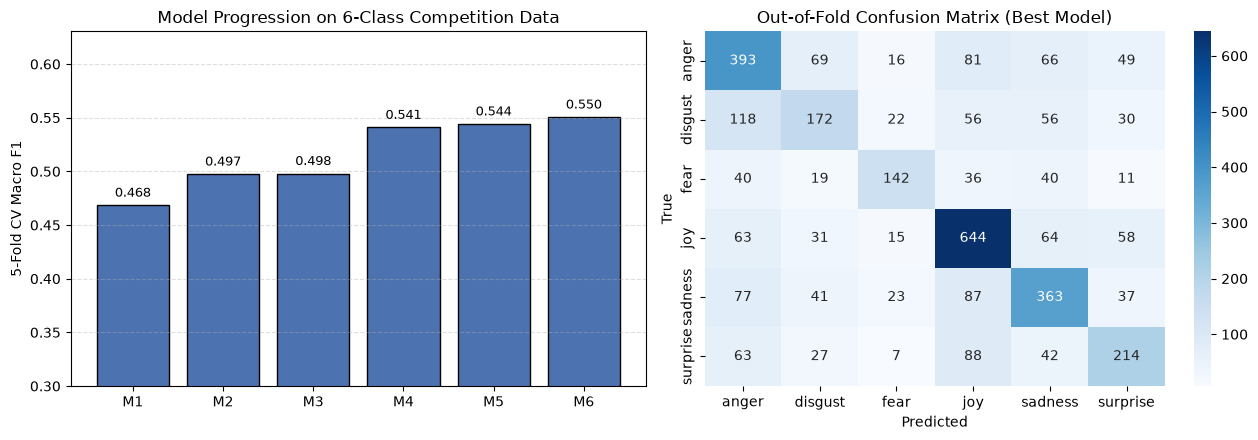

In [3]:
# =============================================================================
# 3. Model Implementation Steps (5-Fold Stratified CV + Submission Generation)
# =============================================================================
# Evaluate five models on 5-fold StratifiedKFold (macro F1, matching competition metric),
# handle class imbalance (joy=875 vs fear=288) via class_weight='balanced',
# compare out-of-fold macro F1, and generate `kaggle_data/submission.csv`.

from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.neural_network import MLPClassifier
from sklearn.svm import LinearSVC

y_train = train_df["label"].to_numpy()
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# Baseline unigram TF-IDF
base_vec = TfidfVectorizer(min_df=2)
X_tr_base = base_vec.fit_transform(train_df["clean"])
X_te_base = base_vec.transform(test_df["clean"])

def eval_cv(name, model_fn, X_tr):
    """Run 5-fold StratifiedKFold CV and return OOF predictions + metrics."""
    oof_preds = np.empty_like(y_train)
    for tr_idx, va_idx in skf.split(X_tr, y_train):
        clf = model_fn()
        clf.fit(X_tr[tr_idx], y_train[tr_idx])
        oof_preds[va_idx] = clf.predict(X_tr[va_idx])
    return {
        "model": name,
        "cv_macro_f1": round(f1_score(y_train, oof_preds, average="macro"), 4),
        "cv_accuracy": round(accuracy_score(y_train, oof_preds), 4),
    }, oof_preds

candidates = [
    ("1. Baseline Unigram TF-IDF + LinearSVC", lambda: LinearSVC(C=1.0, random_state=SEED), X_tr_base),
    ("2. Word+Char TF-IDF + Balanced LinearSVC", lambda: LinearSVC(C=0.4, class_weight="balanced", random_state=SEED), X_tr_word_char),
    ("3. MiniLM Only + Balanced LogisticRegression", lambda: LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED), X_tr_minilm),
    ("4. Hybrid (TF-IDF+MiniLM+Style) + Balanced LinearSVC", lambda: LinearSVC(C=0.35, class_weight="balanced", random_state=SEED), X_tr_hybrid),
    ("5. Hybrid + Balanced LogisticRegression", lambda: LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED), X_tr_hybrid),
]

rows = []
oof_map = {}
for name, fn, Xtr in candidates:
    row, oof = eval_cv(name, fn, Xtr)
    rows.append(row)
    oof_map[name] = oof

# 6. Soft-Voting Ensemble: Calibrated Hybrid LinearSVC + Hybrid LogisticRegression + MiniLM MLP
def fit_predict_ensemble(X_tr_hyb, X_tr_emb, y_tr, X_ev_hyb, X_ev_emb):
    m1 = CalibratedClassifierCV(LinearSVC(C=0.35, class_weight="balanced", random_state=SEED), cv=3)
    m2 = LogisticRegression(C=2.0, class_weight="balanced", max_iter=1000, random_state=SEED)
    m3 = MLPClassifier(hidden_layer_sizes=(128, 64), alpha=0.1, max_iter=300, early_stopping=True, random_state=SEED)
    m1.fit(X_tr_hyb, y_tr)
    m2.fit(X_tr_hyb, y_tr)
    m3.fit(X_tr_emb, y_tr)
    probs = (
        0.45 * m1.predict_proba(X_ev_hyb)
        + 0.35 * m2.predict_proba(X_ev_hyb)
        + 0.20 * m3.predict_proba(X_ev_emb)
    )
    return m1.classes_[np.argmax(probs, axis=1)]

oof_ens = np.empty_like(y_train)
for tr_idx, va_idx in skf.split(X_tr_hybrid, y_train):
    oof_ens[va_idx] = fit_predict_ensemble(
        X_tr_hybrid[tr_idx], X_tr_minilm[tr_idx], y_train[tr_idx],
        X_tr_hybrid[va_idx], X_tr_minilm[va_idx],
    )
ens_name = "6. Soft-Voting Ensemble (Hybrid SVM + Hybrid LR + MiniLM MLP)"
rows.append({
    "model": ens_name,
    "cv_macro_f1": round(f1_score(y_train, oof_ens, average="macro"), 4),
    "cv_accuracy": round(accuracy_score(y_train, oof_ens), 4),
})
oof_map[ens_name] = oof_ens

summary_df = pd.DataFrame(rows)
print("=== 5-Fold Stratified CV Results (6-Class Kaggle Competition Data) ===")
print(summary_df.to_string(index=False))

best_idx = summary_df["cv_macro_f1"].idxmax()
best_name = summary_df.loc[best_idx, "model"]
best_oof = oof_map[best_name]
print(f"\nBest CV model: {best_name} (Macro F1 = {summary_df.loc[best_idx, 'cv_macro_f1']:.4f})")
print("\nOut-of-Fold Classification Report (Best Model):")
print(classification_report(y_train, best_oof, labels=LABELS, digits=4))

# Fit final selected model on all 3,360 training posts and write submission.csv
if best_name == ens_name:
    test_preds = fit_predict_ensemble(X_tr_hybrid, X_tr_minilm, y_train, X_te_hybrid, X_te_minilm)
else:
    best_fn = [fn for n, fn, _ in candidates if n == best_name][0]
    best_Xtr = [Xtr for n, _, Xtr in candidates if n == best_name][0]
    Xte_lookup = {id(X_tr_base): X_te_base, id(X_tr_word_char): X_te_word_char,
                  id(X_tr_minilm): X_te_minilm, id(X_tr_hybrid): X_te_hybrid}
    final_clf = best_fn().fit(best_Xtr, y_train)
    test_preds = final_clf.predict(Xte_lookup[id(best_Xtr)])

sub_df = pd.DataFrame({"post_id": test_df["post_id"], "label": test_preds})
assert list(sub_df.columns) == list(sample_sub.columns) and len(sub_df) == len(sample_sub)
sub_df.to_csv("kaggle_data/submission.csv", index=False)
print("\nSaved kaggle_data/submission.csv — predicted test class distribution:")
print(sub_df["label"].value_counts().reindex(LABELS).to_dict())

# Plot CV progression and 6x6 confusion matrix
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
x = np.arange(len(summary_df))
axes[0].bar(x, summary_df["cv_macro_f1"], color="#4c72b0", edgecolor="black")
for i, v in enumerate(summary_df["cv_macro_f1"]):
    axes[0].text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=9)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f"M{i+1}" for i in range(len(summary_df))])
axes[0].set_ylim(0.30, max(summary_df["cv_macro_f1"]) + 0.08)
axes[0].set_ylabel("5-Fold CV Macro F1")
axes[0].set_title("Model Progression on 6-Class Competition Data")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

cm = confusion_matrix(y_train, best_oof, labels=LABELS)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=LABELS, yticklabels=LABELS, ax=axes[1])
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("True")
axes[1].set_title("Out-of-Fold Confusion Matrix (Best Model)")

plt.tight_layout()
plt.show()
